# Analyse models — two at a time

Pick two model IDs below and run top to bottom. Everything in §1–§7 is recomputed from the
**archived C2ST window-feature matrices** in each ladder run's `artifacts.pkl`, so no model is
loaded and nothing is rolled out. §8 is the only section that needs a checkpoint, and it is
off by default.

**Read every AUC against the real-vs-real floor (≈0.476), not against 0.5.** The floor is the
AUC a classifier reaches separating real fish from *other real fish* — that is the ceiling of
achievable indistinguishability, and it is stored in every run.

Cost, measured: **~9 minutes** with the defaults (permutation importance and ablation dominate),
**~5 minutes** with `FAST = True`. `DO_ROLLOUTS = True` adds ~3 minutes on CPU.

## Configuration

`MODEL_A` / `MODEL_B` accept either a **J-id** from the paper table (`"J3" … "J25"`) or a raw
`"run:model_name"` pair for rungs with no J-id — e.g. `"wall1:mlp_joint_re_swap_psib_rej"` or
`"psire2:mlp_joint_re_swap_psit"`. Run the cell after this one to list everything available.

In [2]:
MODEL_A, MODEL_B = "rej", "J23"

DO_ROLLOUTS = False   # §8 only. Needs torch + data/bouts_GsizeMotionSingle.csv. Adds a few min.
FAST        = False   # cheaper importance/ablation: ~9 min -> ~5 min, noisier feature ranking
SEED        = 0       # matches every archived run (colab_run_ladder.py default)

In [3]:
import ast, io, pickle, sys, warnings, zipfile
from pathlib import Path

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
# ladder artefacts are pickled on Colab under numpy 2; this env may be numpy 1
if not hasattr(np, "_core"):
    import numpy.core as _nc
    for _n in ("numpy._core", "numpy._core.multiarray", "numpy._core.numeric",
               "numpy._core.umath", "numpy._core._multiarray_umath"):
        try:
            sys.modules[_n] = __import__(_n.replace("numpy._core", "numpy.core"), fromlist=["x"])
        except Exception:
            pass
warnings.filterwarnings("ignore", category=RuntimeWarning)   # empty-bin nanmean in the profiles
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")  # RF n_jobs noise

import evaluate as E
import generative_metrics as GM

plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110})
# palette shared with model_lineage.tex / the slide deck
WIN, LOSE, NEUT, REAL, GEN = "#006E3C", "#AA1E1E", "#787878", "#3C3C3C", "#1F3B8C"
CA, CB = "#1F3B8C", "#B5651D"                    # model A / model B
GC = {"turn": "#1F3B8C", "distance": "#0F8A6A", "dt": "#B5651D",
      "dot-dist": "#7A4FA3", "radial": "#AA1E1E"}

# cost knobs -- permutation importance is ~60 s per model per replicate at PERM_REPEATS=3
IMP_REPS, PERM_REPEATS, ABL_REPS = (1, 2, 1) if FAST else (2, 3, 2)
print(f"FAST={FAST}: importance over {IMP_REPS} replicate(s), n_repeats={PERM_REPEATS}; "
      f"ablation over {ABL_REPS} replicate(s)")

FAST=False: importance over 2 replicate(s), n_repeats=3; ablation over 2 replicate(s)


## Registry — J-id → (run, model)

The J-ids exist only in the write-up, not in the code, so the mapping lives here. Every row was
checked against the paper table by matching all four archived numbers
(`bits_per_bout`, `bits_dist`, `c2st_auc`, `c2st_traj_auc`) — the `PAPER` self-check below
re-asserts that at load time, so a wrong entry fails loudly instead of silently plotting the
wrong model.

`RUN_INDEX` is discovered by scanning `*_out/` and `ladder_*_results.zip`, so rungs added later
are selectable as `"run:model"` without editing this file.

In [4]:
# id -> (run tag, zoo model name, what this rung adds)
REG = {
    "J3":  ("joint",  "mlp_joint_h128_shoal",                                  "base (shoal)"),
    "J6":  ("jkin3",  "mlp_joint_h128_shoal_contain",                          "+ containment"),
    "J8":  ("jkin3",  "mlp_joint_h128_shoal_contain_vig",                      "+ vigor"),
    "J9":  ("jkin3",  "mlp_joint_h128_shoal_contain_kfb_vig",                  "+ vigor + kfb"),
    "J10": ("jindiv", "mlp_joint_h128_shoal_contain_kfb_vig_indiv",            "+ indiv"),
    "J16": ("latent", "mlp_joint_re_add",                                      "latent + vigor"),
    "J17": ("reswap", "mlp_joint_re_swap",                                     "latent, vigor off"),
    "J19": ("psij1",  "mlp_joint_h128_shoal_contain_kfb_vig_indiv_psit",       "J10 + psi-frame + dt-snap"),
    "J20": ("psij2",  "mlp_joint_h128_shoal_contain_kfb_vig_indiv_psit_basis", "J19 + border basis"),
    "J22": ("psire",  "mlp_joint_re_swap_psit",                                "J17 + psi-frame + dt-snap"),
    "J23": ("psire2", "mlp_joint_re_swap_psit_basis",                          "J22 + border basis"),
    "J25": ("psire3", "mlp_joint_re_swap_psit_basis_bgain",                    "J23 + border-gain latent (m=3)"),
}

# Round-1 rungs (2026-08-24). No J-ids, so they are keyed by their checkpoint label. All four
# ladders branch off J23, which is why they have no shared control arm: every flag is key-gated
# and a refit with all of them absent reproduces psire2_out/ladder_re_swap_psib.pt exactly.
#
# `rej` = contain_mode='reject': shallow-border REJECTION replaces the shell ramp of centre_bias.
# A sample that would land in the shallow rim is redrawn, and `bulk` (the turn bias) stays fitted
# with 0 first in its grid so the search decides whether any bias survives -- it picks 0.
# Rejection is a GENERATION-time change on the bit-identical J23 net, so psib_rej has exactly
# J23's Metric A. It consumes a variable number of variates per bout, so it can never be CRN
# paired bout-for-bout against a non-reject arm; replicate-level pairing is unaffected.
REG.update({
    "psib_rej":       ("wall1",  "mlp_joint_re_swap_psib_rej",       "J23 + shallow-border REJECTION"),
    "psib_rej_noise": ("wall1",  "mlp_joint_re_swap_psib_rej_noise", "psib_rej + noise-aug training"),
    "psib_ks3":       ("kstim1", "mlp_joint_re_swap_psib_ks3",       "J23 + K_stim=3 stimulus memory"),
    "psib_ks3_rej":   ("kstim1", "mlp_joint_re_swap_psib_ks3_rej",   "psib_ks3 + REJECTION"),
    "psib_noise":     ("noise1", "mlp_joint_re_swap_psib_noise",     "J23 + noise-aug training"),
    "psib_noise_ks3": ("noise1", "mlp_joint_re_swap_psib_noise_ks3", "psib_noise + K_stim=3"),
    "psib_m3w":       ("gain1",  "mlp_joint_re_swap_psib_m3w",       "J23 + m=3 latent, wide gain grid"),
    "psib_m3w_bgain": ("gain1",  "mlp_joint_re_swap_psib_m3w_bgain", "psib_m3w + border-gain latent"),
    "re_swap_psib3":  ("psire3", "mlp_joint_re_swap_psit_basis_m3",  "J23 + m=3 latent (narrow grid)"),
})

# short hands for the round-1 rungs, so the treatment name alone is enough to select one
ALIAS = {"rej": "psib_rej", "rej_noise": "psib_rej_noise",
         "ks3": "psib_ks3", "ks3_rej": "psib_ks3_rej",
         "noise": "psib_noise", "noise_ks3": "psib_noise_ks3",
         "m3w": "psib_m3w", "m3w_bgain": "psib_m3w_bgain", "bgain": "psib_m3w_bgain",
         "m3": "re_swap_psib3"}

# the published row, for the self-check: bits_per_bout, bits_dist, c2st_auc, c2st_traj_auc, bfs, |dth|W1
PAPER = {
    "J3":  (7.6857, 4.6212, 0.5935, 0.8688, 0.031,  6.89),
    "J6":  (7.6857, 4.6212, 0.5909, 0.8529, 0.031,  6.76),
    "J8":  (7.6857, 4.6212, 0.5782, 0.8116, 0.072,  6.93),
    "J9":  (7.6857, 4.6212, 0.6333, 0.7414, 0.061,  6.83),
    "J10": (7.6857, 4.6212, 0.5061, 0.7039, 0.187, 12.59),
    "J16": (7.6832, 4.5698, 0.6482, 0.7735, 0.332, 10.29),
    "J17": (7.6791, 4.5608, 0.5212, 0.7285, 0.189,  8.55),
    "J19": (7.6845, 4.6127, 0.5569, 0.7091, 0.138,  7.76),
    "J20": (7.6757, 4.5990, 0.5207, 0.6706, 0.127,  7.18),
    "J22": (7.6883, 4.5560, 0.5019, 0.7270, 0.183,  8.62),
    "J23": (7.6588, 4.5540, 0.5265, 0.6739, 0.243,  8.54),
    "J25": (7.6525, 4.5479, 0.6370, 0.7420, 0.137,  8.67),
}

# following_gap_h / _static_h changed definition on this date (honest travel-frame bearing);
# runs archived before it are not comparable to runs archived after on those two columns only.
H_DEF_CHANGE = pd.Timestamp("2026-08-11")


def _ast_consts(path, names):
    '''Pull top-level dict literals out of a module WITHOUT importing it (colab_run_ladder
    imports torch at module level; we only want LADDERS / LABEL).'''
    out = {}
    try:
        tree = ast.parse(Path(path).read_text(encoding="utf-8"))
    except Exception:
        return out
    for node in tree.body:
        if isinstance(node, ast.Assign):
            for t in node.targets:
                if isinstance(t, ast.Name) and t.id in names:
                    try:
                        out[t.id] = ast.literal_eval(node.value)
                    except Exception:
                        pass
    return out

_C = _ast_consts(ROOT / "colab_run_ladder.py", {"LADDERS", "LABEL"})
LADDERS, LABEL = _C.get("LADDERS", {}), _C.get("LABEL", {})


def _norm_results(df):
    '''Older runs write the model column as the unnamed index; newer ones name it "model".'''
    return df.rename(columns={"Unnamed: 0": "model"}).set_index("model")


def _sources():
    '''run tag -> (kind, path). Prefer the unzipped *_out dir; fall back to the results zip.'''
    src = {}
    for z in sorted(ROOT.glob("ladder_*_results.zip")):
        src[z.name[len("ladder_"):-len("_results.zip")]] = ("zip", z)
    for d in sorted(ROOT.glob("*_out")):
        if (d / "results.csv").exists() and (d / "artifacts.pkl").exists():
            src[d.name[:-len("_out")]] = ("dir", d)
    return src

SOURCES = _sources()


def _read_member(run, member, binary=False):
    kind, path = SOURCES[run]
    if kind == "dir":
        return (path / member).read_bytes()
    with zipfile.ZipFile(path) as z:
        return z.read(member)


def _build_index():
    idx = {}
    for run in SOURCES:
        try:
            idx[run] = list(_norm_results(pd.read_csv(io.BytesIO(_read_member(run, "results.csv")))).index)
        except Exception:
            pass
    return idx

RUN_INDEX = _build_index()
print(f"{len(RUN_INDEX)} archived runs, "
      f"{len({m for v in RUN_INDEX.values() for m in v})} distinct models")
_missing = [k for k, (r, n, _) in REG.items() if n not in RUN_INDEX.get(r, [])]
print("\nselectable ids:")
_alias_of = {v: k for k, v in ALIAS.items()}
for k, (r, n, t) in REG.items():
    a = _alias_of.get(k, "")
    print(f"  {k:16s} {'(' + a + ')' if a else '':12s} {r:8s} {t}"
          + ("   [ARCHIVE MISSING]" if k in _missing else ""))
print("\n...or any 'run:model_name'. Runs available: " + ", ".join(sorted(RUN_INDEX)))

32 archived runs, 53 distinct models

selectable ids:
  J3                            joint    base (shoal)
  J6                            jkin3    + containment
  J8                            jkin3    + vigor
  J9                            jkin3    + vigor + kfb
  J10                           jindiv   + indiv
  J16                           latent   latent + vigor
  J17                           reswap   latent, vigor off
  J19                           psij1    J10 + psi-frame + dt-snap
  J20                           psij2    J19 + border basis
  J22                           psire    J17 + psi-frame + dt-snap
  J23                           psire2   J22 + border basis
  J25                           psire3   J23 + border-gain latent (m=3)
  psib_rej         (rej)        wall1    J23 + shallow-border REJECTION
  psib_rej_noise   (rej_noise)  wall1    psib_rej + noise-aug training
  psib_ks3         (ks3)        kstim1   J23 + K_stim=3 stimulus memory
  psib_ks3_rej     (ks3_rej)

In [5]:
_RUNS = {}

def load_run(run):
    '''-> dict(res, panel, likA, art, src, mtime) for one ladder run, cached.'''
    if run in _RUNS:
        return _RUNS[run]
    if run not in SOURCES:
        raise KeyError(f"no archive for run {run!r}; have {sorted(SOURCES)}")
    kind, path = SOURCES[run]
    r = dict(
        res=_norm_results(pd.read_csv(io.BytesIO(_read_member(run, "results.csv")))),
        panel=pd.read_csv(io.BytesIO(_read_member(run, "panel.csv"))),
        likA=pd.read_csv(io.BytesIO(_read_member(run, "likA.csv"))),
        art=pickle.loads(_read_member(run, "artifacts.pkl")),
        src=str(path.relative_to(ROOT)),
        # date the run was ARCHIVED -- a directory's own mtime moves whenever anything in it is
        # touched, so use the results file itself
        mtime=pd.Timestamp((path / "results.csv" if kind == "dir" else path).stat().st_mtime,
                           unit="s"),
    )
    _RUNS[run] = r
    return r


def _candidate_runs(model):
    return [r for r, ms in RUN_INDEX.items() if model in ms]


NAME2J = {v[1]: k for k, v in REG.items()}


def resolve_pair(a_id, b_id):
    '''Resolve two ids to (run, model, treatment, display id, id to self-check against).

    If some single run holds BOTH models, use it for both: same run means same quick_results
    call, which means the rollout streams are aligned replicate-for-replicate and the contrast
    is exactly paired.'''
    def split(mid):
        mid = ALIAS.get(mid, mid)
        if ":" in mid:
            run, name = mid.split(":", 1)
            jid = NAME2J.get(name)
            # a raw spec gets the short checkpoint label so the figures stay readable; it is
            # only self-checked against the published row when the run matches too, because
            # the same model name can appear in an archive on a different likelihood scale
            return run, name, f"{run}:{name}", LABEL.get(name, name), \
                (jid if jid and REG[jid][0] == run else None)
        if mid in REG:
            return REG[mid][0], REG[mid][1], REG[mid][2], mid, mid
        near = [k for k in REG if mid.lower() in k.lower()] or \
               [k for k, v in REG.items() if mid.lower() in v[1].lower()]
        raise KeyError(f"unknown model id {mid!r}. "
                       + (f"Did you mean {near}? " if near else "")
                       + f"Known ids: {sorted(REG)} (or aliases {sorted(ALIAS)}, "
                         "or any 'run:model_name').")

    ra, na, ta, da, pa = split(a_id)
    rb, nb, tb, db, pb = split(b_id)
    if na == nb:
        raise ValueError(f"MODEL_A and MODEL_B resolve to the same model ({na}); pick two.")
    if da == db:
        da, db = f"{da} (A)", f"{db} (B)"
    if ra != rb and ":" not in a_id and ":" not in b_id:
        shared = sorted(set(_candidate_runs(na)) & set(_candidate_runs(nb)))
        if shared:
            ra = rb = shared[0]
            print(f"both models live in run {ra!r} -> using it for both (exact replicate pairing)")
    return (ra, na, ta, da, pa), (rb, nb, tb, db, pb)


def handle(mid, run, name, treat, paper_id):
    r = load_run(run)
    art = r["art"]
    if name not in art.get("wins_traj", {}):
        raise KeyError(f"{name!r} not in {run}/artifacts.pkl wins_traj "
                       f"(have {sorted(art.get('wins_traj', {}))})")
    wins = art["wins_traj"][name]
    names = GM.traj_names_for_dim(next(iter(wins[0].values()))[0].shape[1])
    return dict(id=mid, run=run, name=name, treat=treat, label=LABEL.get(name, name),
                paper_id=paper_id, ref_id=NAME2J.get(name),
                res=r["res"].loc[name], panel=r["panel"][r["panel"].model == name],
                likA=r["likA"][r["likA"].model == name], art=art, wins=wins,
                wins_eq=art.get("wins_traj_eq", {}).get(name), names=names,
                groups={g: c for g, c in GM.traj_groups(names).items() if c},
                src=r["src"], mtime=r["mtime"])

_A, _B = resolve_pair(MODEL_A, MODEL_B)
A = handle(_A[3], _A[0], _A[1], _A[2], _A[4])
B = handle(_B[3], _B[0], _B[1], _B[2], _B[4])
MODELS = [A, B]
COL = {A["id"]: CA, B["id"]: CB}
FLOOR = float(A["art"]["neg_control_traj"])
# shared by every figure below, so the sections stay runnable in any order after this cell
order = [g for g in ["turn", "distance", "dt", "dot-dist", "radial"] if g in A["groups"]]
g_of = {f: g for g, c in A["groups"].items() for f in c}
h, TOPN = .38, 15
print(f"\nA = {A['id']}  {A['name']}\n    run {A['run']} ({A['src']})   {A['treat']}")
print(f"B = {B['id']}  {B['name']}\n    run {B['run']} ({B['src']})   {B['treat']}")
print(f"\ntraj C2ST floor (real vs real): {FLOOR:.4f}   <- read every AUC against THIS, not 0.5")


A = psib_rej  mlp_joint_re_swap_psib_rej
    run wall1 (ladder_wall1_results.zip)   J23 + shallow-border REJECTION
B = J23  mlp_joint_re_swap_psit_basis
    run psire2 (psire2_out)   J22 + border basis

traj C2ST floor (real vs real): 0.4761   <- read every AUC against THIS, not 0.5


### Provenance and how far the comparison is allowed to go

The C2ST rollout streams are keyed `(seed, fish_id, rep)` and deliberately **exclude the model
index**, so replicate *r* of one model pairs with replicate *r* of another. That pairing is
exact within a single `quick_results` call. Across two calls it is weaker — the streams start
from the same seed but a different model consumes draws differently — so the cell below checks
the one thing that actually matters for a head-to-head: whether the **real** window matrices
are bit-identical between the two runs. If they are, both models were scored against the same
real reference and the window-level comparison is legitimate.

Metric A is a separate case: it is deterministic given the folds, so `bits_per_bout` is
cross-run comparable per fish *provided both runs used the same fold seed and the same
trainer*. The `fishre` archive is the known exception — it sits ~1 bit higher because two
joint-trainer bugs were fixed after it.

In [6]:
for m in MODELS:
    cfg = m["art"].get("config", {})
    print(f"{m['id']:>5s}  run={m['run']:<8s} folds={cfg.get('folds')} R={cfg.get('R')} "
          f"reps={cfg.get('reps')} epochs={cfg.get('epochs')} seed={cfg.get('seed')} "
          f"archived {m['mtime']:%Y-%m-%d}")

same_run = A["run"] == B["run"]
real_same = True
if not same_run:
    n = min(len(A["wins"]), len(B["wins"]))
    for r in range(n):
        for f in sorted(set(A["wins"][r]) & set(B["wins"][r])):
            ra, rb = A["wins"][r][f][0], B["wins"][r][f][0]
            if ra.shape != rb.shape or not np.allclose(ra, rb):
                real_same = False

print()
if same_run:
    print("PAIRING: same run -> replicate-for-replicate common random numbers. "
          "Paired contrasts below are exact.")
elif real_same:
    print("PAIRING: different runs, but the REAL window matrices are bit-identical, so both "
          "models are scored against the same real reference.\n"
          "         Replicate pairing shares the seed but not draw-for-draw alignment: treat "
          "the paired SE as an estimate, not a guarantee.")
else:
    print("PAIRING: different runs AND the real matrices differ. Compare LEVELS only; the "
          "paired contrast below is not meaningful.")

# --- self-check against the published table -------------------------------------------------
_COLS = ["bits_per_bout", "bits_dist", "c2st_auc", "c2st_traj_auc"]
for m in MODELS:
    got = [float(m["res"][c]) for c in _COLS]
    shown = "  ".join(f"{c}={g:.4f}" for c, g in zip(_COLS, got))
    pid = m["paper_id"]
    if pid in PAPER:
        bad = [(c, w, g) for c, w, g in zip(_COLS, PAPER[pid][:4], got) if abs(w - g) > 1e-3]
        assert not bad, f"{pid} does not match the published row -- registry is wrong. {bad}"
        print(f"\n{m['id']}: matches the published {pid} row  {shown}")
    elif m["ref_id"] in PAPER:
        # same model name, different archive: report the discrepancy instead of asserting --
        # e.g. the fishre run sits ~1 bit higher because two joint-trainer bugs were fixed after it
        d = [f"{c} {g:.4f} vs {w:.4f}" for c, w, g in zip(_COLS, PAPER[m["ref_id"]][:4], got)
             if abs(w - g) > 1e-3]
        print(f"\n{m['id']}: no self-check (raw id). Published {m['ref_id']} row " +
              ("agrees." if not d else "DIFFERS: " + "; ".join(d)))
    else:
        print(f"\n{m['id']}: not in the published table, self-check skipped.  {shown}")

psib_rej  run=wall1    folds=5 R=12 reps=8 epochs=80 seed=0 archived 2026-08-24
  J23  run=psire2   folds=5 R=12 reps=8 epochs=80 seed=0 archived 2026-08-12

PAIRING: different runs, but the REAL window matrices are bit-identical, so both models are scored against the same real reference.
         Replicate pairing shares the seed but not draw-for-draw alignment: treat the paired SE as an estimate, not a guarantee.

psib_rej: not in the published table, self-check skipped.  bits_per_bout=7.6588  bits_dist=4.5540  c2st_auc=0.5409  c2st_traj_auc=0.6821

J23: matches the published J23 row  bits_per_bout=7.6588  bits_dist=4.5540  c2st_auc=0.5265  c2st_traj_auc=0.6739


## §1 Headline scorecard

The paper-table row for both models, rebuilt from local files. `bfs` is the **between-fish
share** — the fraction of total window variance carried by the per-fish means, i.e. how much
individuality the rollouts actually produce. Real fish sit at ≈0.255; a pooled model with no
per-fish structure collapses toward 0.06.

The three likelihood channels are log-densities with respect to **different base measures**
(nats per degree / per pixel / per second), so compare down a column, never across.

In [7]:
def bfs_of(m):
    d = GM.dispersion_report(m["wins"], m["names"])
    return d["between_fish_share"], d["var_ratio"]

rows, DISP = [], {}
for m in MODELS:
    b, vr = bfs_of(m)
    DISP[m["id"]] = (b, vr)
    r = m["res"]
    rows.append({
        "id": m["id"], "model": m["label"], "added": m["treat"], "run": m["run"],
        "turn bits": r["bits_per_bout"], "dist bits": r["bits_dist"], "dt bits": r["bits_dt"],
        "symbol bits": r.get("symbol_bits", np.nan),
        "turn AUC": r["c2st_auc"], "turn sd": r["c2st_auc_sd"],
        "traj AUC": r["c2st_traj_auc"], "traj sd": r["c2st_traj_auc_sd"],
        "bfs": b["gen"], "|dth| W1": m["panel"]["abs_dtheta_w1"].mean(),
    })
score = pd.DataFrame(rows).set_index("id")
ref = pd.Series({"model": "REAL / floor", "added": "", "run": "",
                 "turn AUC": FLOOR, "traj AUC": FLOOR,
                 "bfs": DISP[A["id"]][0]["real"],
                 "|dth| W1": 0.0}, name="target")
pd.set_option("display.width", 220)
print(pd.concat([score, ref.to_frame().T]).to_string(float_format=lambda v: f"{v:.4f}"))

if all(m["paper_id"] in PAPER for m in MODELS):
    print("\nrecomputed vs published (bfs, |dth| W1):")
    for m in MODELS:
        p = PAPER[m["paper_id"]]
        print(f"  {m['id']}: bfs {score.loc[m['id'], 'bfs']:.4f} vs {p[4]:.3f}   "
              f"|dth| W1 {score.loc[m['id'], '|dth| W1']:.3f} vs {p[5]:.2f}")

                 model                           added     run  turn bits  dist bits  dt bits  symbol bits turn AUC  turn sd traj AUC  traj sd    bfs |dth| W1
psib_rej      psib_rej  J23 + shallow-border REJECTION   wall1     7.6588     4.5540   1.4892       1.3267   0.5409   0.0461   0.6821   0.0392 0.2504   8.5605
J23       re_swap_psib              J22 + border basis  psire2     7.6588     4.5540   1.4892       1.3267   0.5265   0.0306   0.6739   0.0465 0.2426   8.5380
target    REAL / floor                                                NaN        NaN      NaN          NaN   0.4761      NaN   0.4761      NaN 0.2551   0.0000


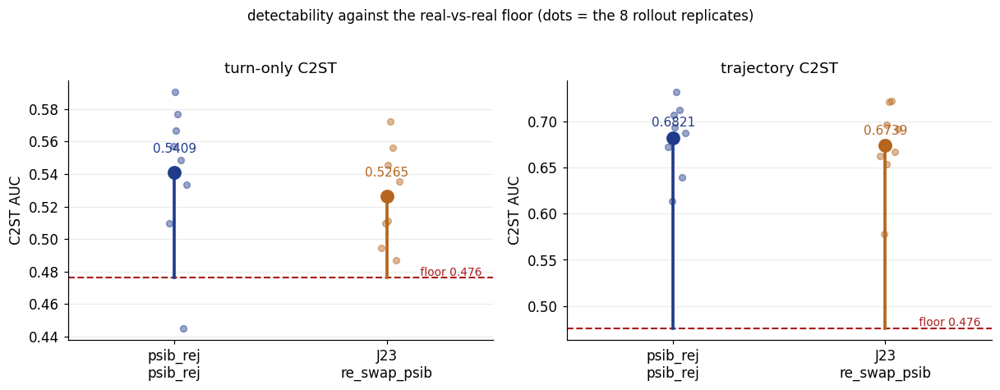

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
for ax, key, reps_key, title in [
        (axes[0], "c2st_auc", "auc_reps", "turn-only C2ST"),
        (axes[1], "c2st_traj_auc", "auc_traj_reps", "trajectory C2ST")]:
    for i, m in enumerate(MODELS):
        reps = np.asarray(m["art"][reps_key][m["name"]], float)
        ax.scatter(np.full(len(reps), i) + np.random.default_rng(0).normal(0, .045, len(reps)),
                   reps, s=26, color=COL[m["id"]], alpha=.45, zorder=3)
        ax.plot([i, i], [FLOOR, float(m["res"][key])], color=COL[m["id"]], lw=2.4, zorder=4)
        ax.plot(i, float(m["res"][key]), "o", ms=10, color=COL[m["id"]], zorder=5)
        ax.text(i, float(m["res"][key]) + .012, f"{float(m['res'][key]):.4f}",
                ha="center", fontsize=10, color=COL[m["id"]])
    ax.axhline(FLOOR, color=LOSE, ls="--", lw=1.4)
    ax.text(1.45, FLOOR, f" floor {FLOOR:.3f}", color=LOSE, fontsize=9, va="bottom", ha="right")
    ax.set_xticks(range(len(MODELS)))
    ax.set_xticklabels([f"{m['id']}\n{m['label']}" for m in MODELS])
    ax.set_xlim(-.5, len(MODELS) - .5)
    ax.set_ylabel("C2ST AUC"); ax.set_title(title)
    ax.grid(axis="y", color="0.92"); ax.set_axisbelow(True)
fig.suptitle("detectability against the real-vs-real floor (dots = the 8 rollout replicates)",
             y=1.02, fontsize=11)
fig.tight_layout(); plt.show()

## §2 What is the trajectory C2ST actually detecting?

The 39 window features split into five groups, and `radial` is deliberately kept separate from
`dot-dist`: radial position is a **containment** property, and folding it into the stimulus
group is exactly the misattribution to avoid.

Three views, because none is sufficient alone:

* **importance** (2a, 2b) says where the forest looked;
* **ablation** (2c) says what the AUC actually loses without a group — the only one that
  supports a claim like *"0.67 → 0.55 without radial"*;
* **univariate separation** (2d) says which single features differ, ignoring the classifier.

They disagree whenever features are correlated, which these are (moments of the same channel),
and C2ST defects **mask each other** — a group can look unimportant purely because a louder
group is saturating the classifier. So read 2c before declaring any channel innocent.

In [9]:
def stack(w):
    '''{fish: (real, gen)} -> X, y (1=real), groups (fish id).'''
    X, y, g = [], [], []
    for fid, (rf, gf) in w.items():
        if len(rf) == 0 or len(gf) == 0:
            continue
        X += [rf, gf]
        y += [np.ones(len(rf)), np.zeros(len(gf))]
        g += [np.full(len(rf), fid), np.full(len(gf), fid)]
    return np.vstack(X), np.concatenate(y), np.concatenate(g)


def auc_cols(w, cols, seed=SEED):
    '''C2ST AUC using only `cols` -- same GroupKFold-by-fish protocol as GM.c2st_auc.'''
    X, y, g = stack(w)
    X = X[:, list(cols)]
    gkf = GroupKFold(n_splits=min(5, len(np.unique(g))))
    out = []
    for tr, te in gkf.split(X, y, g):
        if len(np.unique(y[te])) < 2:
            continue
        clf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1).fit(X[tr], y[tr])
        out.append(roc_auc_score(y[te], clf.predict_proba(X[te])[:, 1]))
    return float(np.mean(out)) if out else np.nan


def importances(m, reps=IMP_REPS, n_repeats=PERM_REPEATS):
    '''Permutation importance averaged over replicates -> DataFrame[feature x replicate].

    feature_names is MANDATORY: without it c2st_importances falls back to the 20-name turn-only
    list, the index degrades to f0..f38 and traj_groups matches nothing.'''
    cols = {}
    for r in range(min(reps, len(m["wins"]))):
        cols[r] = GM.c2st_importances(m["wins"][r], m["names"], seed=SEED,
                                      kind="permutation", n_repeats=n_repeats)
    return pd.DataFrame(cols)

IMP = {}
for m in MODELS:
    print(f"permutation importance for {m['id']} ...", flush=True)
    IMP[m["id"]] = importances(m)
print("done")

permutation importance for psib_rej ...
permutation importance for J23 ...


c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packag

done


c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packag

### §2a Grouped importance — where the classifier looks

Permutation importances are per-feature AUC drops. They do not sum to 1 and can go slightly
negative for irrelevant features, so they are clipped at 0 and normalised before the group
shares are taken.

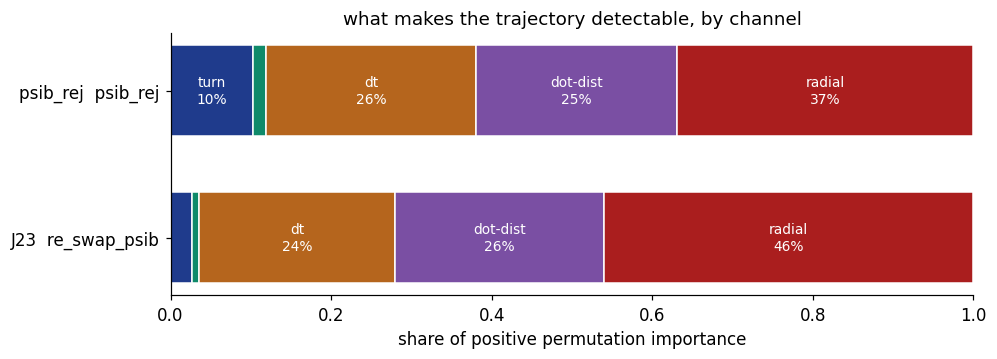

          psib_rej   J23
turn         0.103 0.026
distance     0.016 0.009
dt           0.261 0.245
dot-dist     0.250 0.260
radial       0.369 0.461


In [10]:
def group_shares(imp_series, groups):
    v = imp_series.clip(lower=0)
    tot = max(float(v.sum()), 1e-9)
    return {g: float(v[c].sum()) / tot for g, c in groups.items()}

fig, ax = plt.subplots(figsize=(9.2, 3.4))
for i, m in enumerate(MODELS):
    sh = [group_shares(IMP[m["id"]].mean(axis=1), m["groups"]) for _ in [0]][0]
    left = 0.0
    for g in order:
        w = sh.get(g, 0.0)
        ax.barh(i, w, left=left, color=GC[g], edgecolor="white", height=.62)
        if w > .05:
            ax.text(left + w / 2, i, f"{g}\n{w:.0%}", ha="center", va="center",
                    fontsize=9, color="white")
        left += w
ax.set_yticks(range(len(MODELS)))
ax.set_yticklabels([f"{m['id']}  {m['label']}" for m in MODELS])
ax.set_xlim(0, 1); ax.set_xlabel("share of positive permutation importance")
ax.set_title("what makes the trajectory detectable, by channel")
ax.invert_yaxis()
fig.tight_layout(); plt.show()

print(pd.DataFrame({m["id"]: group_shares(IMP[m["id"]].mean(axis=1), m["groups"])
                    for m in MODELS}).reindex(order).to_string(float_format=lambda v: f"{v:.3f}"))

### §2b Top individual features

The whisker is the spread across replicates. A feature whose whisker crosses its neighbours'
is not reliably ranked above them — the ordering below the top few is usually noise.

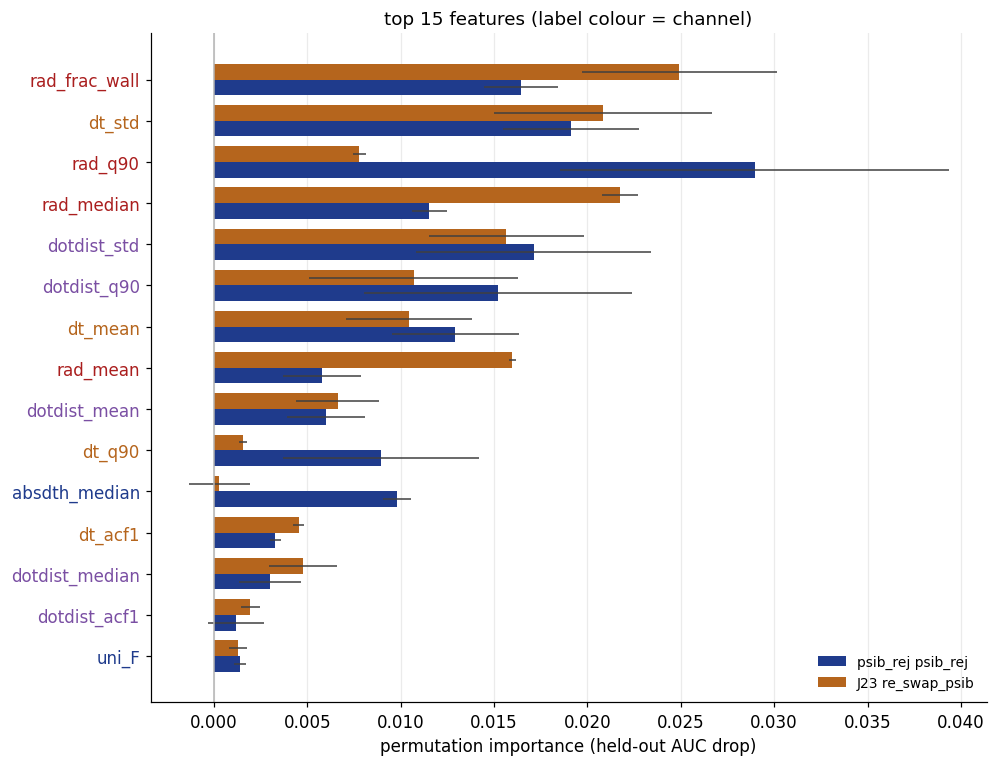

In [11]:
mean_all = sum(IMP[m["id"]].mean(axis=1) for m in MODELS) / len(MODELS)
top = mean_all.sort_values(ascending=False).head(TOPN).index[::-1]

fig, ax = plt.subplots(figsize=(9.2, .38 * TOPN + 1.4))
for i, m in enumerate(MODELS):
    d = IMP[m["id"]].loc[top]
    mu, lo, hi = d.mean(axis=1), d.min(axis=1), d.max(axis=1)
    pos = np.arange(len(top)) + (i - .5) * h
    ax.barh(pos, mu, height=h, color=COL[m["id"]], label=f"{m['id']} {m['label']}")
    if d.shape[1] > 1:
        ax.hlines(pos, lo, hi, color="0.25", lw=1.0)
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"{f}" for f in top])
for t, f in zip(ax.get_yticklabels(), top):
    t.set_color(GC.get(g_of.get(f, "turn"), NEUT))
ax.axvline(0, color="0.7", lw=1)
ax.set_xlabel("permutation importance (held-out AUC drop)")
ax.set_title(f"top {TOPN} features (label colour = channel)")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.grid(axis="x", color="0.92"); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

### §2c Group ablation — the load-bearing view

For each channel: **drop-one** refits the C2ST without that channel's columns (how much
detectability survives without it), and **only-one** refits using nothing else (how much that
channel carries on its own). Drop-one falling to the floor means the channel is the whole
story; only-one near the floor means the channel is genuinely fine.

Two channels can *both* be near-sufficient on their own — that is masking, and it means neither
"drop" number alone tells you what to fix. Read the two panels together.

The dotted baseline is this section's own all-features AUC over `ABL_REPS` replicates, so it
will not equal the 8-replicate figure in §1. Compare within this figure, not across sections.

In [12]:
def ablation(m, reps=ABL_REPS):
    names, groups = m["names"], m["groups"]
    idx = {n: i for i, n in enumerate(names)}
    recs = []
    for r in range(min(reps, len(m["wins"]))):
        w = m["wins"][r]
        recs.append(("all", "all", auc_cols(w, range(len(names)))))
        for g, cols in groups.items():
            keep = [i for n, i in idx.items() if n not in set(cols)]
            recs.append(("drop", g, auc_cols(w, keep)))
            recs.append(("only", g, auc_cols(w, [idx[n] for n in cols])))
    d = pd.DataFrame(recs, columns=["kind", "group", "auc"])
    return d.groupby(["kind", "group"])["auc"].mean()

ABL = {}
for m in MODELS:
    print(f"ablation for {m['id']} ...", flush=True)
    ABL[m["id"]] = ablation(m)
print("done")

ablation for psib_rej ...


c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packag

ablation for J23 ...
done


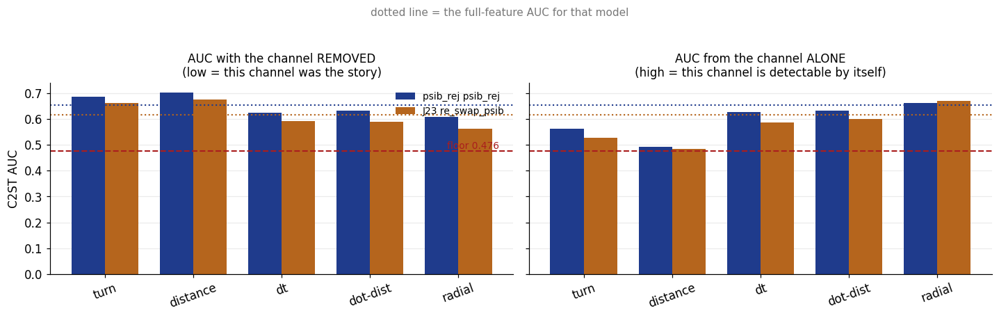

               psib_rej    J23
drop turn        0.6866 0.6606
drop distance    0.7029 0.6751
drop dt          0.6235 0.5903
drop dot-dist    0.6310 0.5888
drop radial      0.6064 0.5615
only turn        0.5617 0.5276
only distance    0.4916 0.4849
only dt          0.6253 0.5855
only dot-dist    0.6330 0.5999
only radial      0.6600 0.6694
all features     0.6537 0.6156


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.0), sharey=True)
x = np.arange(len(order))
for ax, kind, title in [
        (axes[0], "drop", "AUC with the channel REMOVED\n(low = this channel was the story)"),
        (axes[1], "only", "AUC from the channel ALONE\n(high = this channel is detectable by itself)")]:
    for i, m in enumerate(MODELS):
        v = [ABL[m["id"]].get((kind, g), np.nan) for g in order]
        ax.bar(x + (i - .5) * h, v, width=h, color=COL[m["id"]],
               label=f"{m['id']} {m['label']}")
    for i, m in enumerate(MODELS):
        ax.axhline(ABL[m["id"]].get(("all", "all"), np.nan), color=COL[m["id"]], ls=":", lw=1.4)
    ax.axhline(FLOOR, color=LOSE, ls="--", lw=1.4)
    ax.set_xticks(x); ax.set_xticklabels(order, rotation=20)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", color="0.92"); ax.set_axisbelow(True)
axes[0].set_ylabel("C2ST AUC")
axes[0].text(len(order) - .5, FLOOR, f"floor {FLOOR:.3f} ", color=LOSE, fontsize=9,
             ha="right", va="bottom")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("dotted line = the full-feature AUC for that model", y=1.03, fontsize=10, color=NEUT)
fig.tight_layout(); plt.show()

tab = pd.DataFrame({m["id"]: {
    **{f"drop {g}": ABL[m["id"]].get(("drop", g), np.nan) for g in order},
    **{f"only {g}": ABL[m["id"]].get(("only", g), np.nan) for g in order},
    "all features": ABL[m["id"]].get(("all", "all"), np.nan),
} for m in MODELS})
print(tab.to_string(float_format=lambda v: f"{v:.4f}"))

### §2d Univariate separation

Per-feature ROC AUC of real vs generated windows, folded to `|AUC − 0.5| + 0.5` so 0.5 means
identical marginals. No classifier, no cross-validation — this measures how far apart the two
**marginals** are, which is not the same as how well a defect generalises across fish.

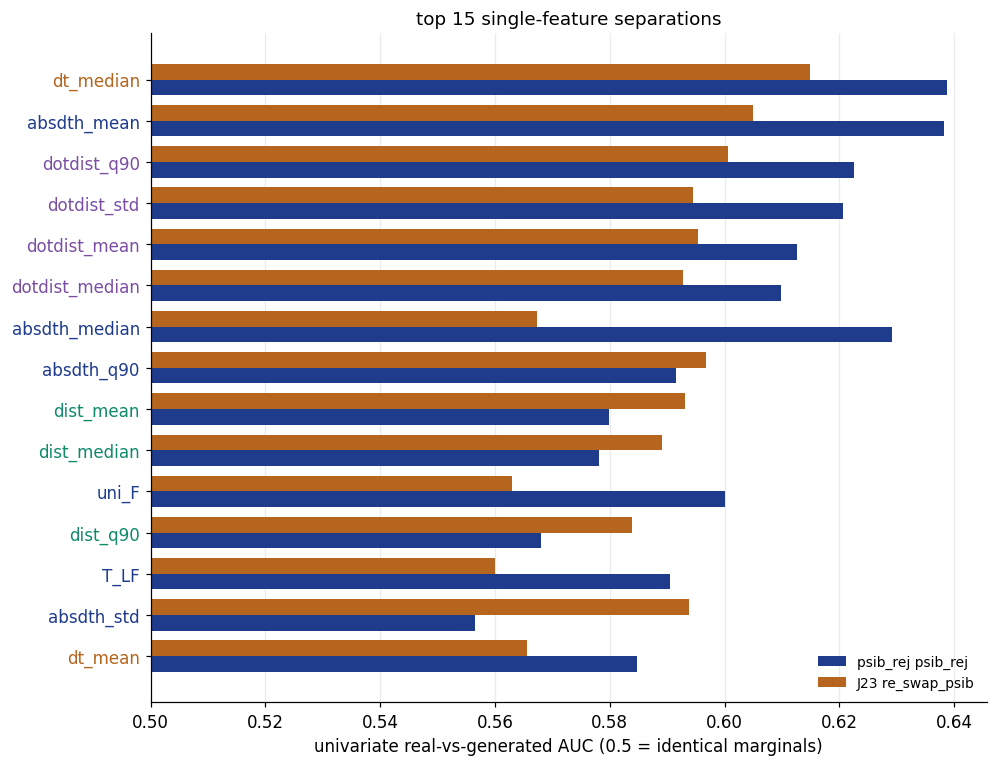

In [14]:
def uni_sep(m, rep=0):
    X, y, _ = stack(m["wins"][rep])
    out = {}
    for j, n in enumerate(m["names"]):
        a = roc_auc_score(y, X[:, j])
        out[n] = max(a, 1 - a)
    return pd.Series(out)

UNI = {m["id"]: uni_sep(m) for m in MODELS}
u_mean = sum(UNI.values()) / len(UNI)
top_u = u_mean.sort_values(ascending=False).head(TOPN).index[::-1]

fig, ax = plt.subplots(figsize=(9.2, .38 * TOPN + 1.4))
for i, m in enumerate(MODELS):
    ax.barh(np.arange(len(top_u)) + (i - .5) * h, UNI[m["id"]].loc[top_u] - .5, height=h,
            left=.5, color=COL[m["id"]], label=f"{m['id']} {m['label']}")
ax.axvline(.5, color="0.7", lw=1)
ax.set_yticks(range(len(top_u))); ax.set_yticklabels(list(top_u))
for t, f in zip(ax.get_yticklabels(), top_u):
    t.set_color(GC.get(g_of.get(f, "turn"), NEUT))
ax.set_xlabel("univariate real-vs-generated AUC (0.5 = identical marginals)")
ax.set_title(f"top {TOPN} single-feature separations")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.grid(axis="x", color="0.92"); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

## §3 Defect leaderboard — magnitude, not just detectability

§2 says what is *detectable*. This says what is *wrong*, and in which direction.

* **standardised gap** = `(mean_gen − mean_real) / sd_real` over windows. Sign is meaningful:
  negative on `rad_mean` means the generated fish sits too close to the centre.
* **variance ratio** = `var_gen / var_real`. Below 1 = under-dispersed (too typical, the
  classic rollout failure), above 1 = over-dispersed.

The real side is replicate-invariant so it is taken from replicate 0; the generated side pools
all replicates.

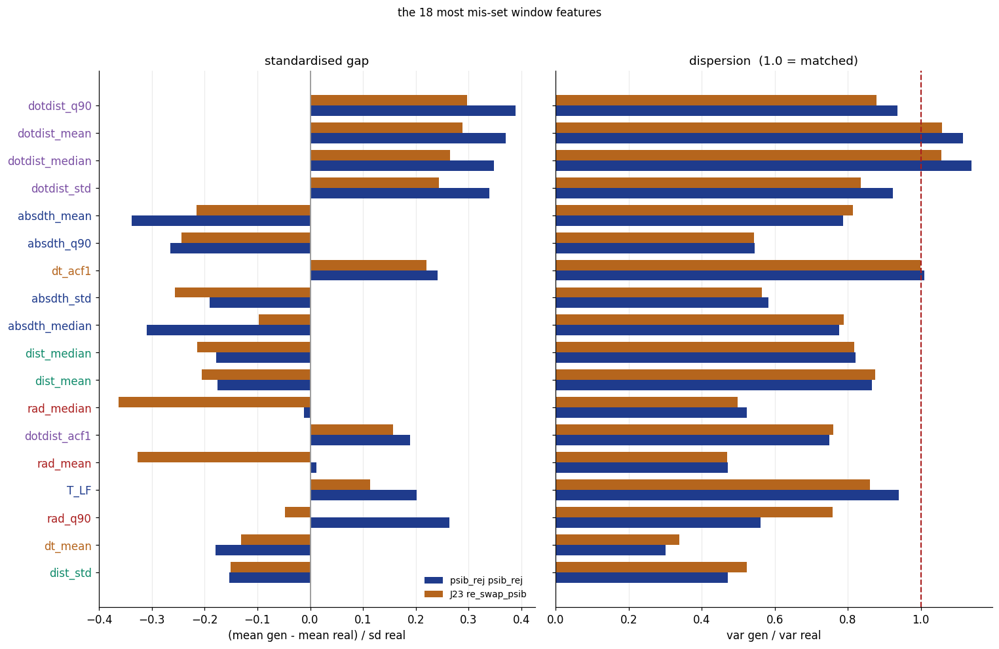

In [15]:
def feat_stats(m):
    R = np.vstack([rf for _, (rf, gf) in m["wins"][0].items()])
    G = np.vstack([gf for w in m["wins"] for _, (rf, gf) in w.items()])
    sdr, vr = R.std(0), R.var(0)
    sdr = np.where(sdr == 0, np.nan, sdr)
    vr = np.where(vr == 0, np.nan, vr)
    return (pd.Series((G.mean(0) - R.mean(0)) / sdr, index=m["names"]),
            pd.Series(G.var(0) / vr, index=m["names"]))

GAP, VRAT = {}, {}
for m in MODELS:
    GAP[m["id"]], VRAT[m["id"]] = feat_stats(m)
dead = [n for n in A["names"] if not np.isfinite(GAP[A["id"]][n])]
if dead:
    print(f"dropped (zero variance in the real windows): {dead}")

TOPG = 18
rank = sum(GAP[k].abs() for k in GAP).dropna().sort_values(ascending=False).head(TOPG).index[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14.0, .40 * TOPG + 1.6), sharey=True)
for i, m in enumerate(MODELS):
    pos = np.arange(len(rank)) + (i - .5) * h
    axes[0].barh(pos, GAP[m["id"]].loc[rank], height=h, color=COL[m["id"]],
                 label=f"{m['id']} {m['label']}")
    axes[1].barh(pos, VRAT[m["id"]].loc[rank], height=h, color=COL[m["id"]])
axes[0].axvline(0, color="0.6", lw=1.2)
axes[0].set_xlabel("(mean gen - mean real) / sd real"); axes[0].set_title("standardised gap")
axes[1].axvline(1, color=LOSE, ls="--", lw=1.4)
axes[1].set_xlabel("var gen / var real"); axes[1].set_title("dispersion  (1.0 = matched)")
axes[0].set_yticks(range(len(rank))); axes[0].set_yticklabels(list(rank))
for t, f in zip(axes[0].get_yticklabels(), rank):
    t.set_color(GC.get(g_of.get(f, "turn"), NEUT))
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
for ax in axes:
    ax.grid(axis="x", color="0.92"); ax.set_axisbelow(True)
fig.suptitle(f"the {TOPG} most mis-set window features", y=1.02, fontsize=11)
fig.tight_layout(); plt.show()

### Channel dispersion and the individuality gap

`var_ratio` per channel and `between_fish_share`, both from `GM.dispersion_report`. The AUC
alone cannot see the difference between a model that is too narrow and one that is too wide,
and those need opposite fixes — one ladder rung once improved the AUC by −0.04 while *halving*
the generated distance dispersion. Read this next to every AUC.

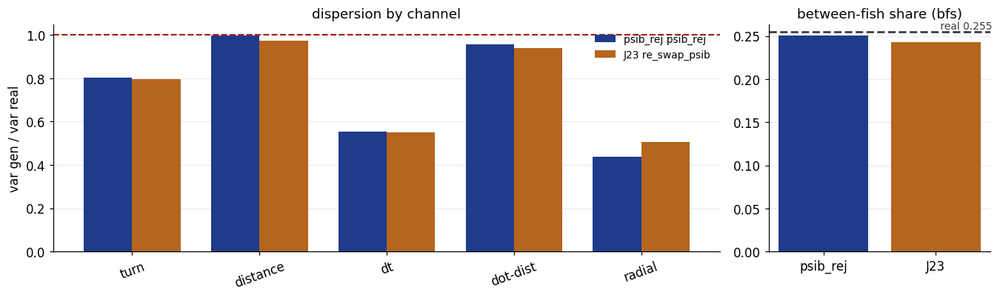

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 3.8),
                         gridspec_kw=dict(width_ratios=[3, 1]))
x = np.arange(len(order))
for i, m in enumerate(MODELS):
    vr = DISP[m["id"]][1]
    axes[0].bar(x + (i - .5) * h, [vr.get(g, np.nan) for g in order], width=h,
                color=COL[m["id"]], label=f"{m['id']} {m['label']}")
axes[0].axhline(1.0, color=LOSE, ls="--", lw=1.4)
axes[0].set_xticks(x); axes[0].set_xticklabels(order, rotation=20)
axes[0].set_ylabel("var gen / var real"); axes[0].set_title("dispersion by channel")
axes[0].legend(frameon=False, fontsize=9)

for i, m in enumerate(MODELS):
    axes[1].bar(i, DISP[m["id"]][0]["gen"], color=COL[m["id"]])
axes[1].axhline(DISP[A["id"]][0]["real"], color=REAL, ls="--", lw=1.8)
axes[1].text(len(MODELS) - .5, DISP[A["id"]][0]["real"],
             f" real {DISP[A['id']][0]['real']:.3f}", color=REAL, fontsize=9,
             va="bottom", ha="right")
axes[1].set_xticks(range(len(MODELS))); axes[1].set_xticklabels([m["id"] for m in MODELS])
axes[1].set_title("between-fish share (bfs)")
for ax in axes:
    ax.grid(axis="y", color="0.92"); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

## §4 Marginal vs temporal

The same rollouts with each behavioural channel rank-mapped onto that fish's real marginal.
Whatever AUC survives that is **temporal structure** the model gets wrong; the difference is
nominally the share attributable to wrong levels.

Three caveats, and the third is not hypothetical for these models. The equalisation touches the
generated side only, and it leaves the radial and dot-distance blocks alone (they are derived
from positions, not resampled channels) — so this applies to turn/distance/interval, not to
containment. Equalised AUC is not a model score on its own: a real model has to get its
marginals right too. And the share **can come out negative** — equalising can make a model
*more* detectable, because the rank map matches each fish's marginal exactly while real windows
scatter around theirs, so it can install a new too-perfect signature. A negative share is
therefore not evidence that the marginals were fine; it means this decomposition does not
cleanly separate the two effects for that model.

psib_rej: raw 0.6821 -> equalised 0.7298 (sd 0.0081), marginal share -0.0477   <- equalising made it MORE detectable -- see the caveat above
J23: raw 0.6739 -> equalised 0.7399 (sd 0.0095), marginal share -0.0660   <- equalising made it MORE detectable -- see the caveat above


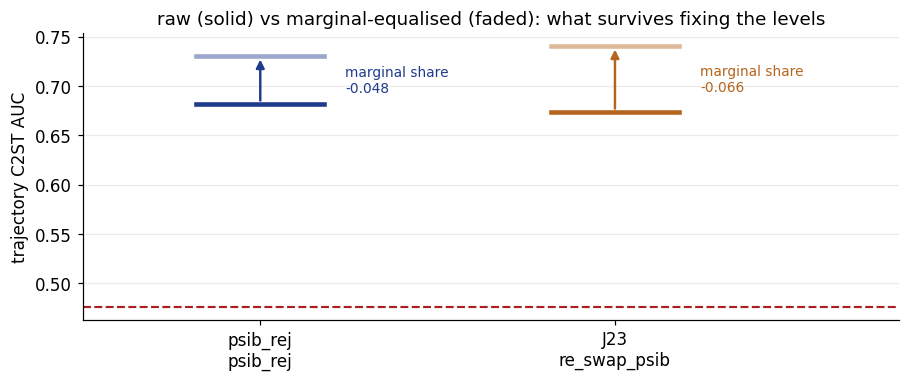

In [17]:
if all(m["wins_eq"] for m in MODELS):
    fig, ax = plt.subplots(figsize=(8.4, 3.6))
    for i, m in enumerate(MODELS):
        raw = float(m["res"]["c2st_traj_auc"])
        eq, sd, _ = GM.c2st_auc_replicates(m["wins_eq"])
        ax.plot([i - .18, i + .18], [raw, raw], color=COL[m["id"]], lw=3)
        ax.plot([i - .18, i + .18], [eq, eq], color=COL[m["id"]], lw=3, alpha=.45)
        ax.annotate("", xy=(i, eq), xytext=(i, raw),
                    arrowprops=dict(arrowstyle="-|>", color=COL[m["id"]], lw=1.6))
        ax.text(i + .24, (raw + eq) / 2, f"marginal share\n{raw - eq:+.3f}",
                fontsize=9, va="center", color=COL[m["id"]])
        note = ("levels carry that much of the detectability" if raw - eq > 0.01 else
                "equalising made it MORE detectable -- see the caveat above" if raw - eq < -0.01
                else "levels carry essentially none of it")
        print(f"{m['id']}: raw {raw:.4f} -> equalised {eq:.4f} (sd {sd:.4f}), "
              f"marginal share {raw - eq:+.4f}   <- {note}")
    ax.axhline(FLOOR, color=LOSE, ls="--", lw=1.4)
    ax.set_xticks(range(len(MODELS)))
    ax.set_xticklabels([f"{m['id']}\n{m['label']}" for m in MODELS])
    ax.set_xlim(-.5, len(MODELS) - .2)
    ax.set_ylabel("trajectory C2ST AUC")
    ax.set_title("raw (solid) vs marginal-equalised (faded): what survives fixing the levels")
    ax.grid(axis="y", color="0.92"); ax.set_axisbelow(True)
    fig.tight_layout(); plt.show()
else:
    print("wins_traj_eq missing from at least one archive -- section skipped")

## §5 Per-fish breakdown

Both metrics aggregate over 15 fish, and the aggregate hides which fish the model fails on.
Fish 6 and 14 are known outliers on the individuality analysis and are marked.

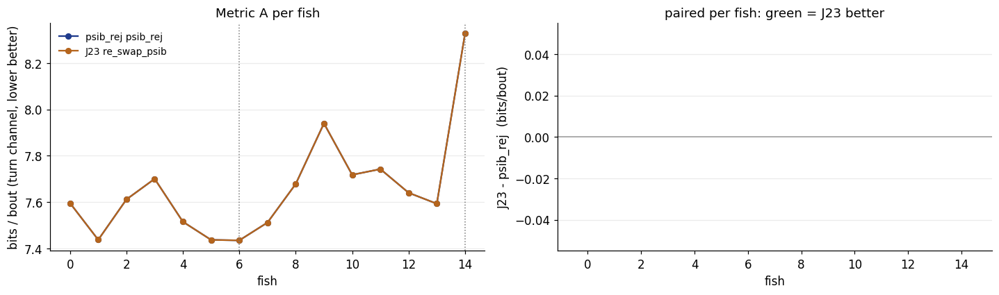

paired_compare (bits_per_bout, lower is better): prefers psib_rej on 0 of 15 fish, J23 on 0
  median delta (psib_rej - J23) +0.0000 [+0.0000, +0.0000]  -> positive means J23 needs fewer bits; wilcoxon p=nan, sign-test p=nan


In [18]:
OUTLIER_FISH = {6, 14}

likA = pd.concat([A["likA"], B["likA"]], ignore_index=True) if A["run"] != B["run"] else \
       load_run(A["run"])["likA"]
likA = likA[likA.model.isin([A["name"], B["name"]])]

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.0))
piv = likA.pivot_table(index="fish_id", columns="model", values="bits_per_bout")
piv = piv[[A["name"], B["name"]]]
for i, m in enumerate(MODELS):
    axes[0].plot(piv.index, piv[m["name"]], "-o", color=COL[m["id"]], ms=5,
                 label=f"{m['id']} {m['label']}")
for f in OUTLIER_FISH & set(piv.index):
    axes[0].axvline(f, color=NEUT, ls=":", lw=1)
axes[0].set_xlabel("fish"); axes[0].set_ylabel("bits / bout (turn channel, lower better)")
axes[0].set_title("Metric A per fish")
axes[0].legend(frameon=False, fontsize=9)

d = (piv[B["name"]] - piv[A["name"]])
axes[1].bar(d.index, d.values, color=[WIN if v < 0 else LOSE for v in d.values])
axes[1].axhline(0, color="0.6", lw=1)
axes[1].set_xlabel("fish")
axes[1].set_ylabel(f"{B['id']} - {A['id']}  (bits/bout)")
axes[1].set_title(f"paired per fish: green = {B['id']} better")
for ax in axes:
    ax.grid(axis="y", color="0.92"); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

pc = E.paired_compare(likA, A["name"], B["name"], "bits_per_bout", higher_better=False)
print(f"paired_compare (bits_per_bout, lower is better): prefers {A['id']} on {pc['prefer_a']} "
      f"of {pc['n_fish']} fish, {B['id']} on {pc['prefer_b']}")
print(f"  median delta ({A['id']} - {B['id']}) {pc['median_delta']:+.4f} "
      f"[{pc['delta_lo']:+.4f}, {pc['delta_hi']:+.4f}]  -> positive means {B['id']} needs fewer "
      f"bits; wilcoxon p={pc['wilcoxon_p']:.4f}, sign-test p={pc['sign_test_p']:.4f}")

per-fish detectability for psib_rej ...


c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\arthu\mp_semiCL_behavior\.venv\Lib\site-packag

per-fish detectability for J23 ...


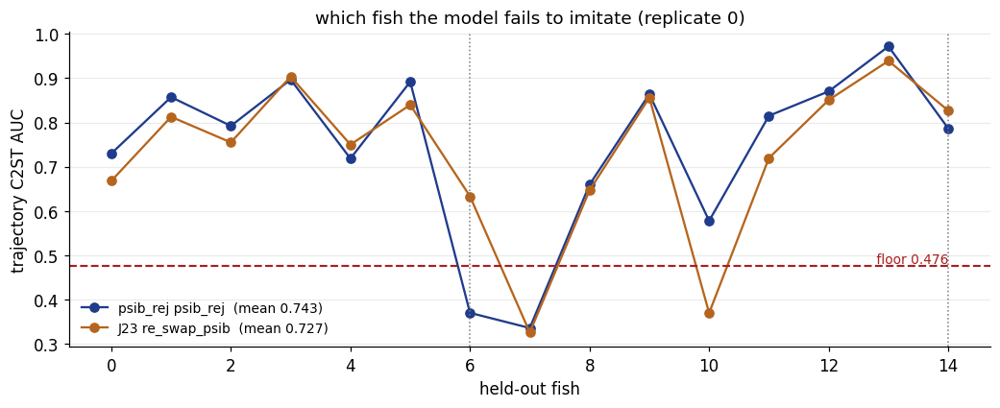

In [19]:
def per_fish_auc(m, rep=0, seed=SEED):
    '''Hold one fish out, train on the other 14, score that fish. This is the per-fish version
    of the same leave-fish-out protocol the reported AUC uses.'''
    X, y, g = stack(m["wins"][rep])
    out = {}
    for fid in np.unique(g):
        tr, te = g != fid, g == fid
        if len(np.unique(y[te])) < 2:
            continue
        clf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1).fit(X[tr], y[tr])
        out[int(fid)] = roc_auc_score(y[te], clf.predict_proba(X[te])[:, 1])
    return pd.Series(out)

PFA = {}
for m in MODELS:
    print(f"per-fish detectability for {m['id']} ...", flush=True)
    PFA[m["id"]] = per_fish_auc(m)

fig, ax = plt.subplots(figsize=(9.6, 4.0))
for m in MODELS:
    s = PFA[m["id"]]
    ax.plot(s.index, s.values, "-o", color=COL[m["id"]], ms=6,
            label=f"{m['id']} {m['label']}  (mean {s.mean():.3f})")
ax.axhline(FLOOR, color=LOSE, ls="--", lw=1.4)
ax.text(max(PFA[A["id"]].index), FLOOR, f" floor {FLOOR:.3f}", color=LOSE, fontsize=9,
        va="bottom", ha="right")
for f in OUTLIER_FISH & set(PFA[A["id"]].index):
    ax.axvline(f, color=NEUT, ls=":", lw=1)
ax.set_xlabel("held-out fish"); ax.set_ylabel("trajectory C2ST AUC")
ax.set_title("which fish the model fails to imitate (replicate 0)")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", color="0.92"); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

## §6 The 21-metric panel, and the realism guards

Each panel metric is a per-fish distance between real and generated; lower is closer. The bars
are means with a fish-level bootstrap CI, and the right panel is the paired per-fish
difference, which cancels the fish-to-fish variation that dominates the absolute levels.

Because the metrics have wildly different units, the ordering is by **normalised** gap: each
metric divided by the larger of the two models' values.

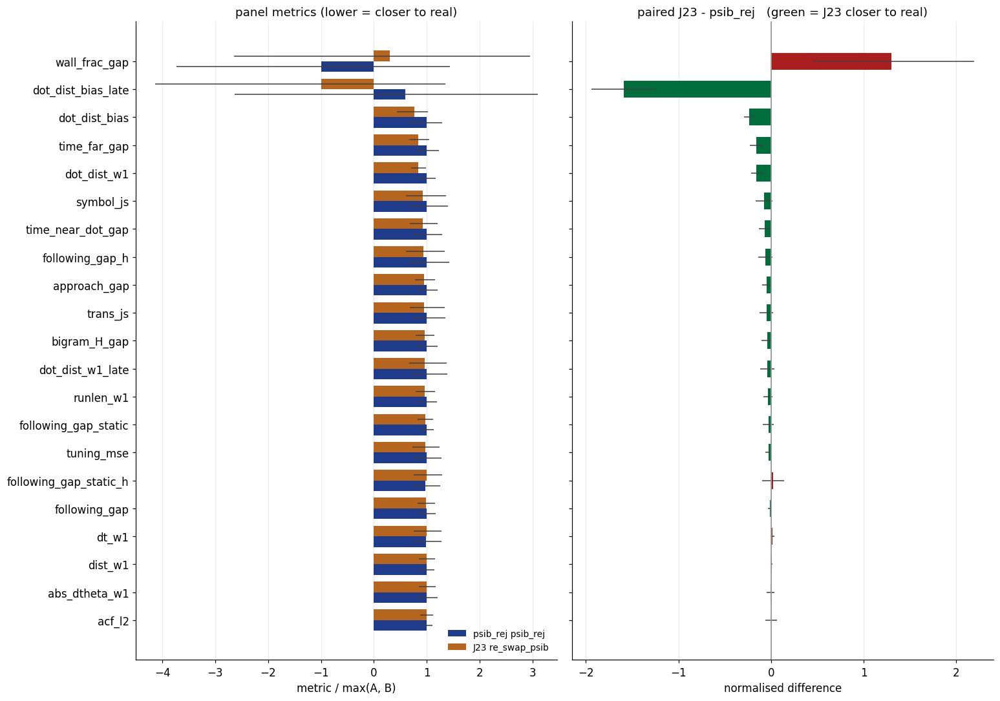

In [20]:
panel = pd.concat([A["panel"], B["panel"]], ignore_index=True)
summ = GM.summarize_panel(panel).set_index("model")

# following_gap_h / _static_h changed definition on 2026-08-11; drop them from a cross-run
# comparison that straddles the change rather than plotting a meaningless delta.
mets = [c for c in GM.PANEL_METRICS if c in summ.columns and summ[c].notna().all()]
straddles = (A["mtime"] < H_DEF_CHANGE) != (B["mtime"] < H_DEF_CHANGE)
if straddles:
    drop = [c for c in mets if c.endswith("_h")]
    if drop:
        print(f"NOTE: the two runs straddle the {H_DEF_CHANGE:%Y-%m-%d} redefinition of the "
              f"honest-bearing following metrics -- dropping {drop}")
        mets = [c for c in mets if c not in drop]

va = summ.loc[A["name"], mets].astype(float).abs()
vb = summ.loc[B["name"], mets].astype(float).abs()
rel = va.combine(vb, max)
rel = rel.where(rel > 0, 1.0)                  # a metric that is 0 for both needs no scaling
mets = list(((va - vb).abs() / rel).sort_values().index)   # biggest A-vs-B disagreement on top

fig, axes = plt.subplots(1, 2, figsize=(14.2, .40 * len(mets) + 1.6), sharey=True)
yy = np.arange(len(mets))
for i, m in enumerate(MODELS):
    v = summ.loc[m["name"], mets].astype(float).to_numpy()
    lo = summ.loc[m["name"], [c + "_lo" for c in mets]].astype(float).to_numpy()
    hi = summ.loc[m["name"], [c + "_hi" for c in mets]].astype(float).to_numpy()
    scale = rel[mets].to_numpy()
    pos = yy + (i - .5) * h
    axes[0].barh(pos, v / scale, height=h, color=COL[m["id"]], label=f"{m['id']} {m['label']}")
    axes[0].hlines(pos, lo / scale, hi / scale, color="0.25", lw=1.0)

dd = []
for c in mets:
    pa = A["panel"].set_index("fish_id")[c]
    pb = B["panel"].set_index("fish_id")[c]
    j = pa.index.intersection(pb.index)
    diff = (pb[j] - pa[j]).to_numpy(float)
    mu, lo, hi = E.fish_bootstrap_ci(diff)
    dd.append((mu, lo, hi))
dd = np.array(dd)
axes[1].barh(yy, dd[:, 0] / rel[mets].to_numpy(),
             color=[WIN if v < 0 else LOSE for v in dd[:, 0]], height=.6)
axes[1].hlines(yy, dd[:, 1] / rel[mets].to_numpy(), dd[:, 2] / rel[mets].to_numpy(),
               color="0.25", lw=1.0)
axes[1].axvline(0, color="0.6", lw=1.2)
axes[0].set_yticks(yy); axes[0].set_yticklabels(mets)
axes[0].set_xlabel("metric / max(A, B)"); axes[0].set_title("panel metrics (lower = closer to real)")
axes[1].set_xlabel("normalised difference")
axes[1].set_title(f"paired {B['id']} - {A['id']}   (green = {B['id']} closer to real)")
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
for ax in axes:
    ax.grid(axis="x", color="0.92"); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

### Timing and realism guards

These exist because two ladder rungs have now won the AUC while degrading an uncounted
property — one halved the generated distance dispersion, another cut quiescent time from 13.0%
to 6.9% of the session against a real 24.4%. Everything here is plotted as a **deviation from
target**, so a bar of zero length is correct behaviour.

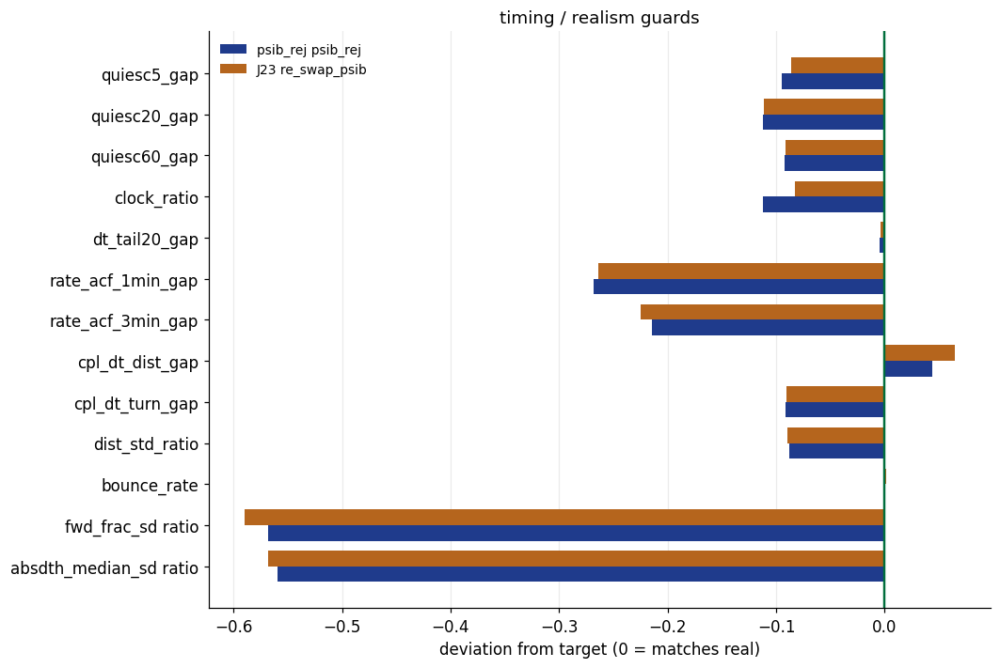

                        psib_rej     J23
quiesc5_gap              -0.0946 -0.0865
quiesc20_gap             -0.1124 -0.1111
quiesc60_gap             -0.0920 -0.0912
clock_ratio              -0.1124 -0.0829
dt_tail20_gap            -0.0043 -0.0040
rate_acf_1min_gap        -0.2679 -0.2635
rate_acf_3min_gap        -0.2146 -0.2247
cpl_dt_dist_gap          +0.0439 +0.0646
cpl_dt_turn_gap          -0.0914 -0.0903
dist_std_ratio           -0.0880 -0.0899
bounce_rate              +0.0000 +0.0011
fwd_frac_sd ratio        -0.5682 -0.5901
absdth_median_sd ratio   -0.5598 -0.5684


In [21]:
TIMING = ["quiesc5_gap", "quiesc20_gap", "quiesc60_gap", "clock_ratio", "dt_tail20_gap",
          "rate_acf_1min_gap", "rate_acf_3min_gap", "cpl_dt_dist_gap", "cpl_dt_turn_gap",
          "dist_std_ratio", "bounce_rate"]
SDPAIR = [("fwd_frac_sd_gen", "fwd_frac_sd_real"), ("absdth_median_sd_gen", "absdth_median_sd_real")]

def target_dev(t, k):
    v = t.get(k, np.nan)
    return v - 1.0 if k.endswith("ratio") else v      # *_gap and bounce_rate target 0

rows = {}
for m in MODELS:
    t = m["art"]["timing"][m["name"]]
    d = {k: target_dev(t, k) for k in TIMING}
    for gen_k, real_k in SDPAIR:
        if t.get(real_k):
            d[gen_k.replace("_sd_gen", "_sd ratio")] = t[gen_k] / t[real_k] - 1.0
    rows[m["id"]] = d
dev = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9.8, .40 * len(dev) + 1.4))
yy = np.arange(len(dev))[::-1]
for i, m in enumerate(MODELS):
    ax.barh(yy + (i - .5) * h, dev[m["id"]], height=h, color=COL[m["id"]],
            label=f"{m['id']} {m['label']}")
ax.axvline(0, color=WIN, lw=1.6)
ax.set_yticks(yy); ax.set_yticklabels(dev.index)
ax.set_xlabel("deviation from target (0 = matches real)")
ax.set_title("timing / realism guards")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="x", color="0.92"); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()
print(dev.to_string(float_format=lambda v: f"{v:+.4f}"))

## §7 Stimulus response

> **Read `following_gap_h`, not `following_gap`.** `following_index` is
> `P(sign(dθ) == sign(bearing)) − 0.5` over moving turn bouts. The plain version scores the
> model's turns against **the real fish's bearing track** — a stimulus the simulated fish never
> saw. These are closed-loop models: they react to their own generated bearing, and once a
> rollout diverges from the real trajectory (a few bouts in) the real bearing sequence is
> unrelated to what the simulated fish was looking at. So `following_gap` collapses to
> "gen index ≈ 0" *by construction*, for any model, however well it follows.
>
> `following_gap_h` scores against `stim_angle_gen` — the bearing the model actually reacted
> to — with a frame-matched real reference. Measured on this dataset: real following index is
> +0.1244 in the ori frame and +0.1351 in the travel frame, and the psi-era models sit around
> `gap_h` 0.028, i.e. they reproduce ~80% of real following strength. The plain `gap` reads
> ~0.123 for the same models, which is the whole signal and is an artefact of the frame.

Two further known artefacts. `dot_dist_bias` is roughly two-thirds a block-onset placement
artefact rather than a behavioural drift, and the generated attraction to the shoal is too
**strong**, not too weak — the real gap is range *tuning* (an inverted-U with a set point
around 43 px), which §8 draws if you turn rollouts on.

building records once for the travel-frame reference (a few s; §8 reuses) ...
real following index:  ori frame +0.1244   travel frame +0.1351


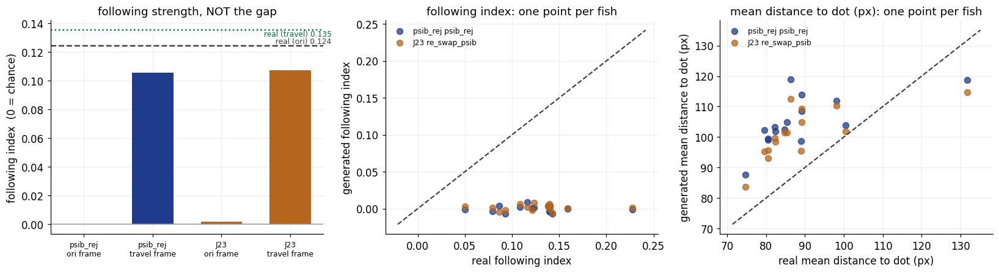

                        psib_rej     J23  real ref  psib_rej / ref  J23 / ref
following_gap             0.1245  0.1229    0.1244          1.0011     0.9881
following_gap_static      0.0598  0.0581    0.0553          1.0819     1.0512
following_gap_h           0.0298  0.0279    0.1351          0.2208     0.2067
following_gap_static_h    0.0245  0.0250       NaN             NaN        NaN
tuning_mse                0.0218  0.0212       NaN             NaN        NaN
dot_dist_w1              18.5564 15.6694   88.9093          0.2087     0.1762
dot_dist_w1_late         13.9746 13.4255       NaN             NaN        NaN
approach_gap              1.5414  1.4637       NaN             NaN        NaN
dot_dist_bias            16.1391 12.3035       NaN             NaN        NaN
time_near_dot_gap         0.0569  0.0529       NaN             NaN        NaN
time_far_gap              0.1189  0.1000       NaN             NaN        NaN

following_gap is FRAME-MISMATCHED for closed-loop models -- rea

In [22]:
STIM = [c for c in ["following_gap", "following_gap_static", "following_gap_h",
                    "following_gap_static_h", "tuning_mse", "dot_dist_w1", "dot_dist_w1_late",
                    "approach_gap", "dot_dist_bias", "time_near_dot_gap", "time_far_gap"]
        if c in panel.columns]
if straddles:
    STIM = [c for c in STIM if not c.endswith("_h")]

# The travel-frame real following index is a property of the DATA, not of any model, and is not
# stored in panel.csv -- so build the records once here. Cached into _REC, which §8 reuses.
_REAL_TRAVEL = np.nan
_bouts = ROOT / "data" / "bouts_GsizeMotionSingle.csv"
if _bouts.exists():
    if globals().get("_REC") is None:
        print("building records once for the travel-frame reference (a few s; §8 reuses) ...",
              flush=True)
        import fit_MLP_border as MB
        _REC = MB.build_border_records(E.load_bouts(str(_bouts)))
    _v = [GM.tuning_curve(r.dtheta, getattr(r, "stim_angle_travel", None), r.moving)[2]
          for r in _REC.values() if getattr(r, "stim_angle_travel", None) is not None]
    if _v:
        _REAL_TRAVEL = float(np.nanmean(_v))
print(f"real following index:  ori frame {panel['real_following_index'].mean():+.4f}"
      f"   travel frame {_REAL_TRAVEL:+.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.2))

# LEFT: the following index on its own scale, never a max-normalised bar -- a bar that is always
# 1.0 for whichever model is larger reads as "the gap is 1.0", which is how this panel gets
# misread. Absolute values against the real level are the only honest form here.
_real_ori = float(panel["real_following_index"].mean())
bars, labs, cols = [], [], []
for m in MODELS:
    bars.append(float(m["panel"]["gen_following_index"].mean()))
    labs.append(f"{m['id']}\nori frame"); cols.append(COL[m["id"]])
    if "following_gap_h" in m["panel"].columns and not straddles and np.isfinite(_REAL_TRAVEL):
        # gap_h is |real_travel - gen_travel|; show it as the implied gen level below real
        bars.append(_REAL_TRAVEL - float(m["panel"]["following_gap_h"].mean()))
        labs.append(f"{m['id']}\ntravel frame"); cols.append(COL[m["id"]])
axes[0].bar(range(len(bars)), bars, color=cols, width=.6)
axes[0].axhline(_real_ori, color=REAL, ls="--", lw=1.6)
axes[0].text(len(bars) - .4, _real_ori, f" real (ori) {_real_ori:.3f}", color=REAL, fontsize=8,
             ha="right", va="bottom")
axes[0].axhline(_REAL_TRAVEL, color=WIN, ls=":", lw=1.6)
axes[0].text(len(bars) - .4, _REAL_TRAVEL, f" real (travel) {_REAL_TRAVEL:.3f}", color=WIN,
             fontsize=8, ha="right", va="top")
axes[0].axhline(0, color="0.6", lw=1)
axes[0].set_xticks(range(len(bars))); axes[0].set_xticklabels(labs, fontsize=8)
axes[0].set_ylabel("following index  (0 = chance)")
axes[0].set_title("following strength, NOT the gap")

for ax, real_c, gen_c, lab in [
        (axes[1], "real_following_index", "gen_following_index", "following index"),
        (axes[2], "real_dot_dist_mean", "gen_dot_dist_mean", "mean distance to dot (px)")]:
    if real_c not in panel.columns:
        ax.set_visible(False); continue
    lim = []
    for m in MODELS:
        p = m["panel"]
        ax.scatter(p[real_c], p[gen_c], s=42, color=COL[m["id"]], alpha=.75,
                   label=f"{m['id']} {m['label']}")
        lim += [p[real_c].min(), p[real_c].max(), p[gen_c].min(), p[gen_c].max()]
    lo, hi = min(lim), max(lim)
    pad = .06 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color=REAL, ls="--", lw=1.4)
    ax.set_xlabel(f"real {lab}"); ax.set_ylabel(f"generated {lab}")
    ax.set_title(f"{lab}: one point per fish")
    ax.legend(frameon=False, fontsize=8)
for ax in axes:
    ax.grid(color="0.93"); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

# raw values, with the relative error where a real reference exists -- no max-normalisation,
# because a bar that is 1.0 for whichever model is larger cannot be read as a magnitude
_ref = {"following_gap": _real_ori, "following_gap_static": float(panel["real_following_index_static"].mean()),
        "following_gap_h": _REAL_TRAVEL, "following_gap_static_h": np.nan,
        "dot_dist_w1": float(panel["real_dot_dist_mean"].mean()) if "real_dot_dist_mean" in panel else np.nan}
rows = {}
for c in STIM:
    r = _ref.get(c, np.nan)
    d = {f"{m['id']}": float(m["panel"][c].mean()) for m in MODELS}
    d["real ref"] = r
    for m in MODELS:
        d[f"{m['id']} / ref"] = d[m["id"]] / r if np.isfinite(r) and r else np.nan
    rows[c] = d
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.4f}"))
print("\nfollowing_gap is FRAME-MISMATCHED for closed-loop models -- read following_gap_h.")

## §8 Optional: local rollouts

Everything above re-analyses stored summaries. This section reloads the two checkpoints and
generates fresh trajectories, which is the only way to see the full distributions and the
spatial profiles. Set `DO_ROLLOUTS = True` in the config cell.

Note these checkpoints are the **all-fish refits** that each ladder run saves "for local
diagnostics" — they are in-sample, unlike the cross-validated numbers above. Read the shapes,
not the levels.

Rollout randomness is keyed `(SEED, fish_id, rep)` and excludes the model, so both models see
the same draws for the same fish — the repo-wide common-random-numbers convention.

In [23]:
def _ckpt_available(m):
    '''Not every archive shipped checkpoints -- kstim1 has none, so its rungs can be analysed
    from the stored matrices but never rolled out locally.'''
    stem = f"ladder_{m['label']}.pt"
    kind, path = SOURCES[m["run"]]
    if kind == "dir" and (path / stem).exists():
        return True
    zp = ROOT / f"ladder_{m['run']}_results.zip"
    if not zp.exists():
        return False
    with zipfile.ZipFile(zp) as z:
        return any(n.endswith(".pt") for n in z.namelist())

_no_ckpt = [m["id"] for m in MODELS if not _ckpt_available(m)]
ROLL_OK = bool(DO_ROLLOUTS) and not _no_ckpt

if not ROLL_OK:
    if not DO_ROLLOUTS:
        print("DO_ROLLOUTS = False -- skipping. Set it True in the config cell to run this section.")
    else:
        print(f"section 8 SKIPPED: no local checkpoint for {', '.join(_no_ckpt)}. "
              "Sections 1-7 are unaffected -- they never need one.")
else:
    import fit_MLP_border as MB, fit_MLP_mix as MX
    import diag_range_profile as DR, diag_border_profile as DB

    _TMP = ROOT / "notebooks" / "_zip_analyse"

    def ckpt_path(m):
        stem = f"ladder_{m['label']}.pt"
        kind, path = SOURCES[m["run"]]
        if kind == "dir" and (path / stem).exists():
            return path / stem
        zp = ROOT / f"ladder_{m['run']}_results.zip"
        if zp.exists():
            with zipfile.ZipFile(zp) as z:
                cands = [n for n in z.namelist() if n == stem] or \
                        [n for n in z.namelist() if n.endswith(".pt")]
                if not cands:
                    raise FileNotFoundError(f"no checkpoint for {m['id']} in {zp.name}")
                _TMP.mkdir(parents=True, exist_ok=True)
                dest = _TMP / cands[0]
                if not dest.exists():
                    dest.write_bytes(z.read(cands[0]))
                return dest
        raise FileNotFoundError(f"no checkpoint for {m['id']} ({stem})")

    records = globals().get("_REC")          # §7 may already have built these
    if records is None:
        records = MB.build_border_records(E.load_bouts(str(ROOT / "data" / "bouts_GsizeMotionSingle.csv")))
        _REC = records
    recs = list(records.values())
    print(f"{len(recs)} fish, {sum(r.n for r in recs)} bouts")

    MDL = {}
    for m in MODELS:
        p = ckpt_path(m)
        MDL[m["id"]] = MX.load_mix(str(p))
        print(f"  {m['id']}: {p.name} -> {type(MDL[m['id']]).__name__}")

    # Two sources, and mixing them up loses the single most important difference in this pair.
    #   * generation-time treatments live in _cfg_feat. Read them from THERE, never from the
    #     boolean attributes (m.vigor / m.indiv), which older checkpoints do not round-trip.
    #   * the fitted per-fish latent (re_m, re_sd, re_gain, ...) is never in _cfg_feat at all;
    #     it is restored onto the MLPMixJointREDensity instance by load_fishre, so for those the
    #     attribute IS the source of truth and a plain joint model simply has none of them.
    CFG_KEYS = ["stim_mode", "border_mode", "psi_ref", "phi_ref", "dt_snap", "K_stim",
                "vigor", "kin_feedback", "centre_bias", "indiv", "wall_reject", "noise_aug"]
    LATENT_KEYS = ["re_m", "re_sd", "re_gain", "re_ghq_k", "re_bgain", "rad_indiv", "dt_latent"]

    def brief(v, n=34):
        if isinstance(v, dict):
            s = "{" + ", ".join(f"{k}={v[k]:.3g}" if isinstance(v[k], float) else str(k)
                                for k in list(v)[:3]) + ("...}" if len(v) > 3 else "}")
        else:
            s = repr(v)
        return s if len(s) <= n else s[:n - 1] + "~"

    def read(mid):
        mdl = MDL[mid]
        d = {k: mdl._cfg_feat.get(k) for k in CFG_KEYS}
        d.update({k: getattr(mdl, k, "-- not this class --") for k in LATENT_KEYS})
        return d

    def same(x, y):
        try:
            return bool(np.all(x == y)) and type(x) is type(y)
        except Exception:
            return False

    cfg = {m["id"]: read(m["id"]) for m in MODELS}
    cf = pd.DataFrame({mid: {k: brief(v) for k, v in d.items()} for mid, d in cfg.items()})
    cf["source"] = ["_cfg_feat" if k in CFG_KEYS else "attribute" for k in cf.index]
    cf["same"] = ["yes" if same(cfg[A["id"]][k], cfg[B["id"]][k]) else "NO" for k in cf.index]
    print(f"\ntreatments  ({type(MDL[A['id']]).__name__} vs {type(MDL[B['id']]).__name__}):")
    print(cf.to_string())
    diff = [k for k in cf.index if cf.loc[k, "same"] == "NO"]
    if diff:
        print("\nfull values for the keys that differ:")
        for k in diff:
            print(f"  {k}:")
            for m in MODELS:
                print(f"    {m['id']}: {cfg[m['id']][k]}")

    def rollout(model, rs, reps=1, seed=SEED):
        return [(r, model.sample(r, np.random.default_rng([seed, int(r.fish_id), rep])))
                for r in rs for rep in range(reps)]

    ROLL = {}
    for m in MODELS:
        print(f"rolling out {m['id']} ...", flush=True)
        ROLL[m["id"]] = rollout(MDL[m["id"]], recs, reps=1, seed=SEED)
    print("done")

DO_ROLLOUTS = False -- skipping. Set it True in the config cell to run this section.


In [24]:
if ROLL_OK:
    def cat(pairs, key, fn=None):
        out = []
        for r, g in pairs:
            v = np.asarray(g[key], float)
            out.append(fn(v) if fn else v)
        return np.concatenate(out)

    real_dth = np.concatenate([np.abs(r.dtheta) for r in recs])
    real_dt = np.concatenate([np.asarray(r.dt_s, float) for r in recs])
    real_dist = np.concatenate([np.asarray(r.distance_px, float) for r in recs])

    fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.0))
    for ax, real, key, fn, lab, rng_ in [
            (axes[0], real_dth, "dtheta", np.abs, "|dtheta|  (deg)", (0, 90)),
            (axes[1], real_dt, "dt_s", None, "inter-bout interval  (s)", (0, 6)),
            (axes[2], real_dist, "distance_px", None, "travel distance  (px)", (0, 30))]:
        bins = np.linspace(*rng_, 60)
        ax.hist(real[np.isfinite(real)], bins=bins, density=True, color="0.85", label="real")
        for m in MODELS:
            v = cat(ROLL[m["id"]], key, fn)
            ax.hist(v[np.isfinite(v)], bins=bins, density=True, histtype="step", lw=1.8,
                    color=COL[m["id"]], label=f"{m['id']} {m['label']}")
        ax.set_xlabel(lab); ax.set_ylabel("density"); ax.set_yscale("log")
        ax.legend(frameon=False, fontsize=8)
    fig.suptitle("behavioural marginals, real vs generated (log density)", y=1.02)
    fig.tight_layout(); plt.show()

In [25]:
if ROLL_OK:
    cx = float(np.median([r.dish_cx for r in recs]))
    cy = float(np.median([r.dish_cy for r in recs]))
    RR = float(np.median([r.dish_R for r in recs]))

    def rnorm_real():
        return np.concatenate([np.hypot(np.asarray(r.x_px, float) - r.dish_cx,
                                        np.asarray(r.y_px, float) - r.dish_cy) / r.dish_R
                               for r in recs])

    def rnorm_gen(pairs):
        out = []
        for r, g in pairs:
            if g.get("x_px") is None:
                continue
            out.append(np.hypot(np.asarray(g["x_px"], float) - r.dish_cx,
                                np.asarray(g["y_px"], float) - r.dish_cy) / r.dish_R)
        return np.concatenate(out) if out else np.array([])

    fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.2))
    bins = np.linspace(0, 1.05, 60)
    rr = rnorm_real()
    axes[0].hist(rr[np.isfinite(rr)], bins=bins, density=True, color="0.85", label="real")
    for m in MODELS:
        v = rnorm_gen(ROLL[m["id"]])
        if len(v):
            axes[0].hist(v[np.isfinite(v)], bins=bins, density=True, histtype="step", lw=1.8,
                         color=COL[m["id"]], label=f"{m['id']} {m['label']}")
            print(f"{m['id']}: mean r/R {np.nanmean(v):.4f}  frac>0.85 {np.nanmean(v > .85):.4f}")
    print(f"real: mean r/R {np.nanmean(rr):.4f}  frac>0.85 {np.nanmean(rr > .85):.4f}")
    axes[0].axvline(.85, color="0.6", ls=":", lw=1.4)
    axes[0].set_xlabel("r / R"); axes[0].set_ylabel("density")
    axes[0].set_title("radial occupancy  (dotted = wall shell)")
    axes[0].legend(frameon=False, fontsize=8)

    # turn-inward profile: heading reconstructed from consecutive GENERATED positions, which is
    # what diag_border_profile does -- feeding the real per-bout heading alongside generated
    # positions computes psi in the wrong frame
    def border_parts(pairs):
        parts = []
        for r, g in pairs:
            x, y = g.get("x_px"), g.get("y_px")
            if x is None:
                continue
            x, y = np.asarray(x, float), np.asarray(y, float)
            ori = np.arctan2(np.diff(y, prepend=y[0]), np.diff(x, prepend=x[0]))
            parts.append(DB._profile(np.asarray(g["dtheta"], float), x, y, ori,
                                     r.dish_cx, r.dish_cy, r.dish_R))
        return parts

    real_parts = [DB._profile(r.dtheta, np.asarray(r.x_px, float), np.asarray(r.y_px, float),
                              np.asarray(r.f_ori_rad, float), r.dish_cx, r.dish_cy, r.dish_R)
                  for r in recs]
    pr = DB._pool(real_parts, "toward")
    axes[1].plot(range(len(pr)), pr, "-o", color=REAL, lw=2.4, ms=7, zorder=5, label="real")
    for m in MODELS:
        p = border_parts(ROLL[m["id"]])
        if p:
            axes[1].plot(range(len(DB.B_LABELS)), DB._pool(p, "toward"), "--s", ms=5, lw=1.8,
                         color=COL[m["id"]], label=f"{m['id']} {m['label']}")
    axes[1].axhline(.5, color="0.85", ls=":")
    axes[1].set_xticks(range(len(DB.B_LABELS))); axes[1].set_xticklabels(DB.B_LABELS)
    axes[1].set_xlabel("distance to border (r/R units)")
    axes[1].set_ylabel("P(turn toward centre)")
    axes[1].set_title("containment: turning inward near the wall")
    axes[1].legend(frameon=False, fontsize=8)
    for ax in axes:
        ax.grid(color="0.93"); ax.set_axisbelow(True)
    fig.tight_layout(); plt.show()

In [26]:
if ROLL_OK:
    print("range profiles (this rolls each model out again inside diag_range_profile) ...",
          flush=True)
    rs = DR.real_side(records)
    gs = {m["id"]: DR.gen_side(MDL[m["id"]], records, reps=1, seed=SEED) for m in MODELS}

    fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.2))
    for ax, key, lab, hline in [
            (axes[0], "toward", "P(turn toward shoal)", .5),
            (axes[1], "dr", "E[change in range]  (px)", 0.)]:
        ax.plot(range(len(DR.R_LABELS)), rs[key], "-o", color=REAL, lw=2.6, ms=7, zorder=5,
                label="real")
        for m in MODELS:
            ax.plot(range(len(DR.R_LABELS)), gs[m["id"]][key], "--s", ms=5, lw=1.8,
                    color=COL[m["id"]], label=f"{m['id']} {m['label']}")
        ax.axhline(hline, color="0.85", ls=":")
        ax.set_xticks(range(len(DR.R_LABELS))); ax.set_xticklabels(DR.R_LABELS, rotation=20)
        ax.set_xlabel("distance to shoal  (px)"); ax.set_ylabel(lab)
        ax.grid(color="0.93"); ax.set_axisbelow(True)
        ax.legend(frameon=False, fontsize=8)
    axes[0].set_title("range tuning: the inverted-U")
    axes[1].set_title("restoring force (zero crossing = set point)")
    print(f"real set point {DR._zero_crossing(rs['dr'], rs['rmid']):.1f} px")
    for m in MODELS:
        g = gs[m["id"]]
        print(f"{m['id']} set point {DR._zero_crossing(g['dr'], g['rmid']):.1f} px   "
              f"radial {g.get('radial')}")
    fig.tight_layout(); plt.show()

In [27]:
if ROLL_OK:
    SHOW = [r.fish_id for r in recs][:3]
    fig, axes = plt.subplots(len(MODELS) + 1, len(SHOW), figsize=(4.2 * len(SHOW), 4.0 * (len(MODELS) + 1)))
    axes = np.atleast_2d(axes)
    for j, fid in enumerate(SHOW):
        r = records[fid]
        axes[0, j].plot(r.x_px, r.y_px, lw=.7, color=REAL)
        axes[0, j].set_title(f"real  fish {fid}", fontsize=10)
        for i, m in enumerate(MODELS):
            gg = [g for rr, g in ROLL[m["id"]] if rr.fish_id == fid]
            if gg and gg[0].get("x_px") is not None:
                axes[i + 1, j].plot(gg[0]["x_px"], gg[0]["y_px"], lw=.7, color=COL[m["id"]])
            axes[i + 1, j].set_title(f"{m['id']} {m['label']}  fish {fid}", fontsize=10)
    for ax in axes.ravel():
        ax.add_patch(plt.Circle((cx, cy), RR, fill=False, color="0.6", lw=1.2))
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_xlim(cx - 1.1 * RR, cx + 1.1 * RR); ax.set_ylim(cy - 1.1 * RR, cy + 1.1 * RR)
        for s in ax.spines.values():
            s.set_visible(False)
    fig.suptitle("one session per fish: real (top) vs generated", y=1.005)
    fig.tight_layout(); plt.show()

## §9 Verdict

Generated from the numbers above. The paired contrast uses the per-replicate AUC vectors, which
cancels the shared rollout noise; with only 8 replicates the SE estimate is itself noisy, so
the RESOLVED / within-noise label is a guide and not a verdict on its own.

In [28]:
from scipy import stats as _st

print("=" * 78)
for m in MODELS:
    gap, vr = GAP[m["id"]].dropna(), VRAT[m["id"]].dropna()
    top3 = gap.abs().sort_values(ascending=False).head(3).index
    sh = group_shares(IMP[m["id"]].mean(axis=1), m["groups"])
    dominant = max(sh, key=sh.get)
    full = ABL[m["id"]].get(("all", "all"), np.nan)
    drops = {g: full - ABL[m["id"]].get(("drop", g), np.nan) for g in order}
    load = max(drops, key=lambda g: (drops[g] if np.isfinite(drops[g]) else -np.inf))
    solo = {g: ABL[m["id"]].get(("only", g), np.nan) for g in order}
    near = [g for g, v in solo.items() if np.isfinite(v) and v > full - .05]

    print(f"\n{m['id']}  {m['label']}   ({m['treat']})")
    print(f"  traj AUC {float(m['res']['c2st_traj_auc']):.4f} vs floor {FLOOR:.4f} "
          f"-> {float(m['res']['c2st_traj_auc']) - FLOOR:+.4f} above indistinguishable")
    print(f"  worst-set features: " +
          ", ".join(f"{f} ({gap[f]:+.2f} sd)" for f in top3))
    print(f"  classifier looks mostly at '{dominant}' ({sh[dominant]:.0%} of importance); "
          f"removing '{load}' costs the most AUC ({drops[load]:.4f} of {full:.4f})")
    if len(near) > 1:
        print(f"  MASKING: {', '.join(near)} are each near-sufficient alone "
              f"({', '.join(f'{g} {solo[g]:.3f}' for g in near)}) -- fixing one may reveal, "
              f"not remove, the others")
    under = [g for g, v in DISP[m["id"]][1].items() if np.isfinite(v) and v < .75]
    if under:
        print(f"  UNDER-DISPERSED channels (var gen/real < 0.75): {', '.join(under)}")
    print(f"  individuality: bfs {DISP[m['id']][0]['gen']:.3f} against real "
          f"{DISP[m['id']][0]['real']:.3f}")

print("\n" + "=" * 78)
ta = np.asarray(A["art"]["auc_traj_reps"][A["name"]], float)
tb = np.asarray(B["art"]["auc_traj_reps"][B["name"]], float)
if len(ta) == len(tb) and len(ta) > 1:
    d = tb - ta
    se = float(np.std(d, ddof=1) / np.sqrt(len(d)))
    t = float(np.mean(d)) / max(se, 1e-12)
    crit = float(_st.t.ppf(.975, len(d) - 1))
    flag = "RESOLVED" if abs(t) > crit else "within noise"
    better = B["id"] if np.mean(d) < 0 else A["id"]
    print(f"traj C2ST, {B['id']} - {A['id']}: {np.mean(d):+.4f} "
          f"(paired SE {se:.4f}, t={t:+.1f}, n={len(d)}, crit {crit:.1f})  {flag}")
    print(f"  -> {better} is the less detectable model" +
          ("" if flag == "RESOLVED" else ", but the difference is not resolved at n=8"))
    if not same_run:
        print("  NOTE: the two models come from different runs, so this pairing shares the seed "
              "but not draw-for-draw alignment.")
else:
    print("replicate vectors differ in length -- no paired contrast")

_da = float(B['res']['bits_per_bout']) - float(A['res']['bits_per_bout'])
print(f"\nMetric A (turn bits/bout), {B['id']} - {A['id']}: {_da:+.4f} "
      f"({'better' if _da < 0 else 'worse'} -- lower is better)")


psib_rej  psib_rej   (J23 + shallow-border REJECTION)
  traj AUC 0.6821 vs floor 0.4761 -> +0.2060 above indistinguishable
  worst-set features: dotdist_q90 (+0.39 sd), dotdist_mean (+0.37 sd), dotdist_median (+0.35 sd)
  classifier looks mostly at 'radial' (37% of importance); removing 'radial' costs the most AUC (0.0473 of 0.6537)
  MASKING: dt, dot-dist, radial are each near-sufficient alone (dt 0.625, dot-dist 0.633, radial 0.660) -- fixing one may reveal, not remove, the others
  UNDER-DISPERSED channels (var gen/real < 0.75): dt, radial
  individuality: bfs 0.250 against real 0.255

J23  re_swap_psib   (J22 + border basis)
  traj AUC 0.6739 vs floor 0.4761 -> +0.1978 above indistinguishable
  worst-set features: rad_median (-0.36 sd), rad_mean (-0.33 sd), dotdist_q90 (+0.30 sd)
  classifier looks mostly at 'radial' (46% of importance); removing 'radial' costs the most AUC (0.0542 of 0.6156)
  MASKING: dt, dot-dist, radial are each near-sufficient alone (dt 0.585, dot-dist 0.600,